# Credit Card Spending Volume (SV) Decline Analysis
### Merchant-Level Root Cause & Customer Risk Model

**Masalah bisnis:** SV kartu kredit H2 2019 turun 0,8% YoY setelah H1 tumbuh 1,1%.
Merchant/MCC mana penyebabnya, apa driver-nya, dan nasabah mana yang berisiko?

**Dataset:** IBM TabFormer (sintetis), 24,4 juta transaksi, 2.000 nasabah, 6.146 kartu.
Scope: kartu kredit, transaksi clean (tanpa refund, error, fraud, dan $0), 2017–2019.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, zipfile
import pandas as pd
import numpy as np

BASE = '/content/drive/MyDrive/'
OUT = BASE + 'sv_project/'
ZIP = OUT + 'credit_card_transactions-ibm_v2.csv.zip'
os.makedirs(OUT, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# ===== 1) USERS: ID = nomor baris =====
users = pd.read_csv(OUT + 'sd254_users.csv')
users.insert(0, 'user', np.arange(len(users), dtype='int16'))
for c in ['Per Capita Income - Zipcode', 'Yearly Income - Person', 'Total Debt']:
    users[c] = users[c].str.replace('$', '', regex=False).astype(float)
users = users.rename(columns={
    'Current Age': 'age', 'Gender': 'gender', 'City': 'city', 'State': 'state',
    'Per Capita Income - Zipcode': 'zip_income', 'Yearly Income - Person': 'income',
    'Total Debt': 'total_debt', 'FICO Score': 'fico', 'Num Credit Cards': 'num_cards'})
users = users[['user', 'age', 'gender', 'city', 'state', 'zip_income', 'income', 'total_debt', 'fico', 'num_cards']]

In [3]:
# ===== 2) CARDS: buang data sensitif =====
cards = pd.read_csv(OUT + 'sd254_cards.csv')
cards = cards.rename(columns={
    'User': 'user', 'CARD INDEX': 'card', 'Card Brand': 'card_brand', 'Card Type': 'card_type',
    'Has Chip': 'has_chip', 'Credit Limit': 'credit_limit', 'Acct Open Date': 'acct_open'})
cards['credit_limit'] = cards['credit_limit'].str.replace('$', '', regex=False).astype(float)
cards['acct_open'] = pd.to_datetime(cards['acct_open'], format='%m/%Y')
cards = cards[['user', 'card', 'card_brand', 'card_type', 'has_chip', 'credit_limit', 'acct_open']]
cards[['user', 'card']] = cards[['user', 'card']].astype({'user': 'int16', 'card': 'int8'})

In [4]:
# ===== 3) TRANSAKSI: baca bertahap, simpan 2017+ =====
dtype = {'User': 'int16', 'Card': 'int8', 'Year': 'int16', 'Month': 'int8', 'Day': 'int8',
         'Merchant Name': 'int64', 'MCC': 'int16'}
parts = []
with zipfile.ZipFile(ZIP) as z, z.open('credit_card_transactions-ibm_v2.csv') as f:
    for ch in pd.read_csv(f, chunksize=2_000_000, dtype=dtype):
        ch = ch[ch['Year'] >= 2017]
        if len(ch):
            parts.append(ch)
tx = pd.concat(parts, ignore_index=True)
del parts

tx.columns = ['user', 'card', 'year', 'month', 'day', 'time', 'amount', 'use_chip',
              'merchant_id', 'merchant_city', 'merchant_state', 'zip', 'mcc', 'errors', 'is_fraud']
tx['amt'] = tx['amount'].str.replace('$', '', regex=False).astype('float32')
tx['trans_dt'] = pd.to_datetime(tx[['year', 'month', 'day']]) + pd.to_timedelta(tx['time'] + ':00')
tx['ym'] = tx['trans_dt'].dt.to_period('M').dt.to_timestamp()

tx['is_refund'] = tx['amt'] < 0
tx['is_error'] = tx['errors'].notna()
tx['is_fraud'] = tx['is_fraud'].eq('Yes')
tx['is_clean'] = ~tx['is_refund'] & ~tx['is_error'] & ~tx['is_fraud']
tx = tx.drop(columns=['amount', 'time'])

In [5]:
# ===== 4) JOIN ke cards =====
n_before = len(tx)
tx = tx.merge(cards[['user', 'card', 'card_type', 'card_brand', 'credit_limit']], on=['user', 'card'], how='left')
assert len(tx) == n_before, 'Jumlah baris berubah setelah join!'
print('Transaksi tanpa pasangan kartu:', tx['card_type'].isna().sum())
print('\nPorsi SV clean 2017-2019 per card_type:')
base = tx[tx['is_clean'] & tx['year'].between(2017, 2019)]
print((base.groupby('card_type')['amt'].sum() / base['amt'].sum() * 100).round(1))

Transaksi tanpa pasangan kartu: 0

Porsi SV clean 2017-2019 per card_type:
card_type
Credit             38.599998
Debit              57.799999
Debit (Prepaid)     3.600000
Name: amt, dtype: float32


In [6]:
# ===== 5) Filter KARTU KREDIT =====
cc = tx[tx['card_type'] == 'Credit'].copy()
for c in ['use_chip', 'merchant_city', 'merchant_state', 'errors', 'card_type', 'card_brand']:
    cc[c] = cc[c].astype('category')

cc.to_parquet(OUT + 'tx_credit_2017_2020.parquet', index=False)
users.to_parquet(OUT + 'users.parquet', index=False)
cards.to_parquet(OUT + 'cards.parquet', index=False)

In [7]:
# ===== 6) VALIDASI =====
print('\nBaris kredit:', f"{len(cc):,}")
print('Range tanggal:', cc['trans_dt'].min(), '->', cc['trans_dt'].max())
print(cc[['is_refund', 'is_error', 'is_fraud', 'is_clean']].sum())
c = cc[cc['is_clean'] & cc['year'].between(2017, 2019)]
print('Nasabah kredit aktif:', c['user'].nunique(), '| Kartu kredit aktif:', c.groupby(['user', 'card']).ngroups)

m = c.groupby('ym').agg(sv=('amt', 'sum'), trx=('amt', 'size'), active_users=('user', 'nunique'))
m['days'] = c.groupby('ym')['trans_dt'].apply(lambda s: s.dt.normalize().nunique())
m['sv_per_day'] = m['sv'] / m['days']
m['mom_per_day_%'] = m['sv_per_day'].pct_change() * 100
m['yoy_%'] = m['sv'].pct_change(12) * 100
pd.set_option('display.float_format', '{:,.1f}'.format)
print(m)


Baris kredit: 1,699,194
Range tanggal: 2017-01-01 00:01:00 -> 2020-02-28 23:58:00
is_refund      86599
is_error       25004
is_fraud        1851
is_clean     1586705
dtype: int64
Nasabah kredit aktif: 980 | Kartu kredit aktif: 1403
                    sv    trx  active_users  days  sv_per_day  mom_per_day_%  \
ym                                                                             
2017-01-01 2,587,858.0  41557           904    31    83,479.3            NaN   
2017-02-01 2,392,229.0  37770           904    28    85,436.8            2.3   
2017-03-01 2,635,668.0  41696           907    31    85,021.5           -0.5   
2017-04-01 2,570,371.2  40803           908    30    85,679.0            0.8   
2017-05-01 2,671,066.8  41937           911    31    86,163.4            0.6   
2017-06-01 2,601,121.5  40974           908    30    86,704.1            0.6   
2017-07-01 2,664,563.2  42146           913    31    85,953.7           -0.9   
2017-08-01 2,629,779.2  42028           909    

# Mapping MCC dan definisi periode

In [8]:
import json
import pandas as pd
import numpy as np

OUT = '/content/drive/MyDrive/sv_project/'
pd.set_option('display.float_format', '{:,.1f}'.format)
pd.set_option('display.width', 200)

In [9]:
cc = pd.read_parquet(OUT + 'tx_credit_2017_2020.parquet')

In [10]:
# 2) Tabel mapping MCC
with open(OUT + 'mcc_codes.json') as f:
    mcc_json = json.load(f)
mcc_map = pd.DataFrame({'mcc': [int(k) for k in mcc_json.keys()],
                        'mcc_desc': [str(v) for v in mcc_json.values()]})

def mcc_group(code):
    # Rentang standar kode MCC untuk Travel & Entertainment
    if 3000 <= code <= 3299 or code == 4511:
        return 'Airlines'
    if 3351 <= code <= 3441 or code == 7512:
        return 'Car Rental'
    if 3501 <= code <= 3999 or code == 7011:
        return 'Hotels & Lodging'
    return 'Others'

mcc_map['mcc_group'] = mcc_map['mcc'].apply(mcc_group)

# Deskripsi MCC 3000-3999 di mcc_codes.json tidak sesuai standar -> pakai nama kelompok
te_map = mcc_map['mcc_group'] != 'Others'
mcc_map.loc[te_map, 'mcc_desc'] = mcc_map.loc[te_map, 'mcc_group'] + ' - MCC ' + mcc_map.loc[te_map, 'mcc'].astype(str)

missing = sorted(set(cc['mcc'].unique()) - set(mcc_map['mcc']))
print('Jumlah MCC di data      :', cc['mcc'].nunique())
print('MCC tanpa deskripsi     :', missing if missing else 'tidak ada')

Jumlah MCC di data      : 109
MCC tanpa deskripsi     : tidak ada


Setiap MCC di rentang ini hanya punya 1 merchant (pola co-brand/brand-specific MCC).
Karena itu deskripsi diganti dengan nama kelompok. Transaksi bernominal $0 (776 baris, mayoritas MCC 4829)
juga dibuang karena membuat jumlah transaksi membengkak.

In [11]:
# 3) Dataset analisis: clean, nominal > 0, 2018-2019
df = cc[cc['is_clean'] & (cc['amt'] > 0) & cc['year'].between(2018, 2019)].copy()
df['amt'] = df['amt'].astype('float64')
print('Transaksi $0 yang dibuang:', (cc['is_clean'] & (cc['amt'] == 0) & cc['year'].between(2018, 2019)).sum())

n_before = len(df)
df = df.merge(mcc_map, on='mcc', how='left')
assert len(df) == n_before, 'Jumlah baris berubah setelah join MCC!'
df['mcc_desc'] = df['mcc_desc'].fillna('Unknown MCC ' + df['mcc'].astype(str))
df['mcc_group'] = df['mcc_group'].fillna('Others')

Transaksi $0 yang dibuang: 776


In [12]:
# 4) Label periode
df['half'] = np.where(df['month'] <= 6, 'H1', 'H2')
df['period'] = df['half'] + '_' + df['year'].astype(str)

for c in ['mcc_desc', 'mcc_group', 'half', 'period']:
    df[c] = df[c].astype('category')

df.to_parquet(OUT + 'cc_clean_2018_2019.parquet', index=False)
mcc_map.to_parquet(OUT + 'mcc_map.parquet', index=False)

In [13]:
# 5) Validasi & ringkasan
print('\nBaris dataset analisis  :', f"{len(df):,}")
h = df.groupby(['half', 'year'], observed=True)['amt'].sum().unstack()
h['delta'] = h[2019] - h[2018]
h['yoy_%'] = h['delta'] / h[2018] * 100
print('\nSV per semester:')
print(h)

h2 = df[df['half'] == 'H2']
y = h2.groupby(['mcc', 'mcc_desc', 'mcc_group', 'year'], observed=True)['amt'].sum().unstack(fill_value=0)
y['delta'] = y[2019] - y[2018]
y['yoy_%'] = y['delta'] / y[2018].replace(0, np.nan) * 100
print('\nTotal delta H2       :', f"{y['delta'].sum():,.1f}")
print('Total MCC turun      :', f"{y.loc[y['delta'] < 0, 'delta'].sum():,.1f}")
print('Total MCC naik       :', f"{y.loc[y['delta'] > 0, 'delta'].sum():,.1f}")
print('\nTop 10 MCC penyumbang penurunan H2 2019:')
print(y.sort_values('delta').head(10).reset_index()[['mcc', 'mcc_desc', 'mcc_group', 2018, 2019, 'delta', 'yoy_%']])
print('\nDelta H2 per mcc_group:')
print(y.groupby('mcc_group', observed=True)[[2018, 2019, 'delta']].sum())


Baris dataset analisis  : 995,421

SV per semester:
year         2018         2019      delta  yoy_%
half                                            
H1   15,402,796.4 15,571,733.0  168,936.6    1.1
H2   15,664,205.3 15,535,609.7 -128,595.6   -0.8

Total delta H2       : -128,595.6
Total MCC turun      : -358,894.0
Total MCC naik       : 230,298.4

Top 10 MCC penyumbang penurunan H2 2019:
year   mcc                       mcc_desc         mcc_group      2018      2019     delta  yoy_%
0     3001            Airlines - MCC 3001          Airlines  88,310.1  55,007.6 -33,302.5  -37.7
1     6300  Insurance Sales, Underwriting            Others 379,884.4 355,528.5 -24,355.9   -6.4
2     3256            Airlines - MCC 3256          Airlines  80,531.3  61,021.4 -19,509.8  -24.2
3     4722                Travel Agencies            Others 239,313.0 220,357.4 -18,955.6   -7.9
4     3000            Airlines - MCC 3000          Airlines  80,459.2  63,526.4 -16,932.8  -21.0
5     5300               

Fungsi Dekomposisi

In [14]:
def logmean(a, b):
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where(np.isclose(a, b), a, (a - b) / (np.log(a) - np.log(b)))

In [15]:
def decompose(data, keys):
    g = (data.groupby(keys + ['year'], observed=True)
             .agg(sv=('amt', 'sum'), trx=('amt', 'size'), users=('user', 'nunique'))
             .unstack('year', fill_value=0))
    out = pd.DataFrame(index=g.index)
    for y in [2018, 2019]:
        out[f'sv_{y}'] = g[('sv', y)]
        out[f'users_{y}'] = g[('users', y)]
        out[f'freq_{y}'] = g[('trx', y)] / g[('users', y)].replace(0, np.nan)
        out[f'ticket_{y}'] = g[('sv', y)] / g[('trx', y)].replace(0, np.nan)
    out['delta'] = out['sv_2019'] - out['sv_2018']
    out['yoy_%'] = out['delta'] / out['sv_2018'].replace(0, np.nan) * 100

    both = (out['sv_2018'] > 0) & (out['sv_2019'] > 0)
    L = pd.Series(0.0, index=out.index)
    L[both] = logmean(out.loc[both, 'sv_2019'].values, out.loc[both, 'sv_2018'].values)
    for f in ['users', 'freq', 'ticket']:
        out[f'c_{f}'] = 0.0
        out.loc[both, f'c_{f}'] = L[both] * np.log(out.loc[both, f'{f}_2019'] / out.loc[both, f'{f}_2018'])
    out.loc[~both, 'c_users'] = out.loc[~both, 'delta']   # merchant baru/hilang

    out['status'] = np.select([out['sv_2018'] == 0, out['sv_2019'] == 0], ['new', 'lost'], 'existing')
    out['check'] = out['delta'] - (out['c_users'] + out['c_freq'] + out['c_ticket'])
    return out

In [16]:
COLS = ['sv_2018', 'sv_2019', 'delta', 'yoy_%', 'users_2018', 'users_2019',
        'freq_2018', 'freq_2019', 'ticket_2018', 'ticket_2019', 'c_users', 'c_freq', 'c_ticket']

In [17]:
h2 = df[df['half'] == 'H2']

In [18]:
tot = decompose(h2.assign(level='TOTAL'), ['level'])
print('=== TOTAL ===');  print(tot[COLS])

=== TOTAL ===
           sv_2018      sv_2019      delta  yoy_%  users_2018  users_2019  freq_2018  freq_2019  ticket_2018  ticket_2019   c_users     c_freq   c_ticket
level                                                                                                                                                    
TOTAL 15,664,205.3 15,535,609.7 -128,595.6   -0.8         912         935      274.1      268.5         62.7         61.9 388,537.5 -322,534.6 -194,598.5


In [19]:
grp = decompose(h2, ['mcc_group'])
print('\n=== MCC GROUP ===');  print(grp[COLS].sort_values('delta'))


=== MCC GROUP ===
                      sv_2018      sv_2019      delta  yoy_%  users_2018  users_2019  freq_2018  freq_2019  ticket_2018  ticket_2019   c_users    c_freq  c_ticket
mcc_group                                                                                                                                                         
Airlines            743,758.2    640,511.2 -103,247.0  -13.9         572         547        1.7        1.6        746.0        722.1 -30,874.2 -49,890.1 -22,482.7
Hotels & Lodging    895,716.9    852,724.1  -42,992.8   -4.8         728         725        4.7        4.5        259.7        259.5  -3,609.3 -38,706.1    -677.4
Car Rental          289,511.7    281,538.6   -7,973.0   -2.8         426         436        2.9        2.7        237.1        236.4   6,624.6 -13,727.1    -870.5
Others           13,735,218.6 13,760,835.8   25,617.2    0.2         912         907      267.9      270.9         56.2         56.0 -75,580.3 152,059.3 -50,861.7


In [20]:
mcc_tbl = decompose(h2, ['mcc_group', 'mcc', 'mcc_desc'])
print('\n=== TOP 15 MCC PENYUMBANG PENURUNAN ===')
print(mcc_tbl[COLS].sort_values('delta').head(15))


=== TOP 15 MCC PENYUMBANG PENURUNAN ===
                                                                   sv_2018   sv_2019     delta  yoy_%  users_2018  users_2019  freq_2018  freq_2019  ticket_2018  ticket_2019   c_users    c_freq  \
mcc_group        mcc  mcc_desc                                                                                                                                                                      
Airlines         3001 Airlines - MCC 3001                         88,310.1  55,007.6 -33,302.5  -37.7         108          77        1.1        1.0        748.4        696.3 -23,801.2  -4,425.8   
Others           6300 Insurance Sales, Underwriting              379,884.4 355,528.5 -24,355.9   -6.4         476         454        3.2        3.2        251.6        247.4 -17,393.7    -820.2   
Airlines         3256 Airlines - MCC 3256                         80,531.3  61,021.4 -19,509.8  -24.2         109          83        1.1        1.1        700.3        693

In [21]:
mer = decompose(h2, ['mcc_group', 'mcc', 'mcc_desc', 'merchant_id'])
print('\n=== MERCHANT: ringkasan per status ===')
print(mer.groupby('status').agg(n_merchant=('delta', 'size'), delta=('delta', 'sum')))

neg = mer[mer['delta'] < 0].sort_values('delta')
print('\nTotal delta merchant turun :', f"{neg['delta'].sum():,.1f}")
print('Porsi top 20 merchant       :', f"{neg['delta'].head(20).sum() / neg['delta'].sum():.1%}")
print('Porsi top 100 merchant      :', f"{neg['delta'].head(100).sum() / neg['delta'].sum():.1%}")
print('\n=== TOP 15 MERCHANT EXISTING PENYUMBANG PENURUNAN ===')
print(mer[mer['status'] == 'existing'].sort_values('delta')[COLS].head(15))


=== MERCHANT: ringkasan per status ===
          n_merchant      delta
status                         
existing        9410 -113,750.6
lost            5072 -702,219.6
new             4891  687,374.6

Total delta merchant turun : -1,944,031.5
Porsi top 20 merchant       : 12.3%
Porsi top 100 merchant      : 24.1%

=== TOP 15 MERCHANT EXISTING PENYUMBANG PENURUNAN ===
                                                                                                sv_2018   sv_2019     delta  yoy_%  users_2018  users_2019  freq_2018  freq_2019  ticket_2018  \
mcc_group        mcc  mcc_desc                                           merchant_id                                                                                                            
Airlines         3001 Airlines - MCC 3001                                -8194607650924472520  88,310.1  55,007.6 -33,302.5  -37.7         108          77        1.1        1.0        748.4   
                 3256 Airlines - MCC 3256          

In [22]:
for name, t in [('total', tot), ('group', grp), ('mcc', mcc_tbl), ('merchant', mer)]:
    print(f'max |check| {name:9s}:', f"{t['check'].abs().max():.4f}")
print('Sum delta MCC = delta total? ', np.isclose(mcc_tbl['delta'].sum(), tot['delta'].sum()))

max |check| total    : 0.0000
max |check| group    : 0.0000
max |check| mcc      : 0.0000
max |check| merchant : 0.0000
Sum delta MCC = delta total?  True


In [23]:
tot.to_csv(OUT + 's3_total.csv')
grp.to_csv(OUT + 's3_group.csv')
mcc_tbl.to_csv(OUT + 's3_mcc.csv')
mer.to_csv(OUT + 's3_merchant.csv')

*   SV H2 2019 turun -128,6 ribu (-0,8% YoY) walaupun nasabah aktif naik dari 912 ke 935. Penyebab penurunannya adalah frekuensi (-322,5 ribu) dan ticket size (-194,6 ribu).
*  Travel & Entertainment (T&E) turun -154,2 ribu: Airlines -103,2 ribu (-13,9%), Hotels -43,0 ribu (-4,8%), Car Rental -8,0 ribu. Angka ini lebih besar dari penurunan bersih. Kategori non-T&E justru naik +25,6 ribu.
*  Driver per merchant: di airline (3001, 3256, 3000, 3132, 3260) penyebabnya nasabah hilang; di hotel 3640 dan Wholesale Clubs 5300 penyebabnya frekuensi turun; di Travel Agencies 4722 dan Department Stores 5311 penyebabnya ticket size turun.


# Bridge nasabah T&E

In [24]:
OUT = '/content/drive/MyDrive/sv_project/'
pd.set_option('display.float_format', '{:,.1f}'.format)
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)

In [25]:
df = pd.read_parquet(OUT + 'cc_clean_2018_2019.parquet')
users = pd.read_parquet(OUT + 'users.parquet')
cards = pd.read_parquet(OUT + 'cards.parquet')

In [26]:
h2 = df[df['half'] == 'H2'].copy()
h2['segment'] = np.where(h2['mcc_group'].astype(str) != 'Others', 'te', 'nonte')

In [27]:
def user_bridge(data, seg_col='segment', target='te'):
    u = data.pivot_table(index='user', columns=[seg_col, 'year'], values='amt',
                         aggfunc='sum', fill_value=0, observed=True)
    u.columns = [f'{s}_{y}' for s, y in u.columns]
    for c in [f'{target}_2018', f'{target}_2019']:
        if c not in u.columns:
            u[c] = 0.0
    other = [c for c in u.columns if not c.startswith(target)]
    u['other_2018'] = u[[c for c in other if c.endswith('2018')]].sum(axis=1)
    u['other_2019'] = u[[c for c in other if c.endswith('2019')]].sum(axis=1)
    u = u[[f'{target}_2018', f'{target}_2019', 'other_2018', 'other_2019']]
    u.columns = ['tgt_2018', 'tgt_2019', 'other_2018', 'other_2019']
    u['tgt_delta'] = u['tgt_2019'] - u['tgt_2018']
    u['other_delta'] = u['other_2019'] - u['other_2018']
    u['total_delta'] = u['tgt_delta'] + u['other_delta']
    u['status'] = np.select(
        [(u['tgt_2018'] > 0) & (u['tgt_2019'] == 0),
         (u['tgt_2018'] == 0) & (u['tgt_2019'] > 0),
         (u['tgt_2018'] == 0) & (u['tgt_2019'] == 0),
         u['tgt_delta'] < 0,
         u['tgt_delta'] > 0],
        ['stopped', 'new', 'none', 'decreased', 'increased'], 'flat')
    return u

In [28]:
def bridge_summary(u):
    b = u.groupby('status').agg(
        n_user=('tgt_delta', 'size'),
        tgt_2018=('tgt_2018', 'sum'), tgt_2019=('tgt_2019', 'sum'),
        tgt_delta=('tgt_delta', 'sum'), other_delta=('other_delta', 'sum'),
        total_delta=('total_delta', 'sum'))
    b.loc['TOTAL'] = b.sum()
    return b

In [29]:
# T&E gabungan
u_te = user_bridge(h2, 'segment', 'te')
print('=== BRIDGE NASABAH: T&E (H2 2019 vs H2 2018) ===')
print(bridge_summary(u_te))


=== BRIDGE NASABAH: T&E (H2 2019 vs H2 2018) ===
           n_user    tgt_2018    tgt_2019  tgt_delta  other_delta  total_delta
status                                                                        
decreased   395.0 1,298,120.4   678,279.7 -619,840.7    152,690.6   -467,150.1
increased   322.0   494,753.7   955,125.1  460,371.4    -96,991.2    363,380.2
new         106.0         0.0   141,369.1  141,369.1    168,258.4    309,627.6
none         45.0         0.0         0.0        0.0    -10,141.3    -10,141.3
stopped      87.0   136,112.6         0.0 -136,112.6   -188,199.3   -324,311.9
TOTAL       955.0 1,928,986.7 1,774,773.9 -154,212.8     25,617.2   -128,595.6


In [30]:
# Khusus Airlines
h2['seg_air'] = np.where(h2['mcc_group'].astype(str) == 'Airlines', 'air', 'nonair')
u_air = user_bridge(h2, 'seg_air', 'air')
print('\n=== BRIDGE NASABAH: AIRLINES ===')
print(bridge_summary(u_air))


=== BRIDGE NASABAH: AIRLINES ===
           n_user  tgt_2018  tgt_2019  tgt_delta  other_delta  total_delta
status                                                                    
decreased   196.0 363,544.9 198,190.7 -165,354.2    -42,474.6   -207,828.7
increased   162.0 146,372.6 258,584.3  112,211.7    -26,223.2     85,988.5
new         189.0       0.0 183,736.2  183,736.2    253,939.7    437,675.9
none        194.0       0.0       0.0        0.0     31,950.0     31,950.0
stopped     214.0 233,840.7       0.0 -233,840.7   -242,540.5   -476,381.2
TOTAL       955.0 743,758.2 640,511.2 -103,247.0    -25,348.6   -128,595.6


In [31]:
# Nasabah 'stopped' T&E: masih aktif di kategori lain?
st = u_te[u_te['status'] == 'stopped']
print('\nNasabah stopped T&E               :', len(st))
print('  -> tidak transaksi apa pun di H2 2019:', (st['other_2019'] == 0).sum())
print('  -> spend non-T&E turun            :', (st['other_delta'] < 0).sum())


Nasabah stopped T&E               : 87
  -> tidak transaksi apa pun di H2 2019: 16
  -> spend non-T&E turun            : 46


In [32]:
lim = (cards[cards['card_type'] == 'Credit']
       .groupby('user')['credit_limit'].sum().rename('credit_limit'))
online = (h2[h2['year'] == 2018]
          .assign(is_online=lambda d: d['use_chip'].astype(str).eq('Online Transaction'))
          .groupby('user')['is_online'].mean().rename('online_share_2018'))

In [33]:
prof = (u_te.join(users.set_index('user')[['age', 'gender', 'income', 'total_debt', 'fico']])
            .join(lim).join(online))
prof['debt_to_income'] = prof['total_debt'] / prof['income'].replace(0, np.nan)

In [34]:
num_cols = ['age', 'income', 'total_debt', 'debt_to_income', 'fico', 'credit_limit',
            'online_share_2018', 'tgt_2018']
print('=== PROFIL NASABAH PER STATUS T&E (median) ===')
print(prof.groupby('status')[num_cols].median())
print('\n=== Komposisi gender per status (%) ===')
print(pd.crosstab(prof['status'], prof['gender'], normalize='index').mul(100).round(1))

=== PROFIL NASABAH PER STATUS T&E (median) ===
           age   income  total_debt  debt_to_income  fico  credit_limit  online_share_2018  tgt_2018
status                                                                                              
decreased 50.0 42,883.0    57,818.0             1.4 713.0      16,400.0                0.1   2,888.8
increased 51.0 40,838.5    58,366.5             1.3 719.0      15,900.0                0.1   1,125.3
new       44.5 37,209.0    43,880.5             1.3 721.0      13,750.0                0.1       0.0
none      50.0 29,562.0    34,007.0             1.3 712.0      12,900.0                0.1       0.0
stopped   52.0 35,331.0    43,042.0             1.3 713.0      14,300.0                0.1   1,307.1

=== Komposisi gender per status (%) ===
gender     Female  Male
status                 
decreased    50.1  49.9
increased    51.2  48.8
new          54.7  45.3
none         40.0  60.0
stopped      55.2  44.8


In [35]:
# Konsentrasi: berapa nasabah yang menyumbang 80% penurunan T&E
neg = prof[prof['tgt_delta'] < 0].sort_values('tgt_delta')
share = neg['tgt_delta'].cumsum() / neg['tgt_delta'].sum()
print('\nNasabah dengan T&E turun                 :', len(neg))
print('Jumlah nasabah penyumbang 80% penurunan  :', (share <= 0.8).sum() + 1)

prof.to_parquet(OUT + 's4_user_te_bridge.parquet')


Nasabah dengan T&E turun                 : 482
Jumlah nasabah penyumbang 80% penurunan  : 232


* Penurunan T&E terkonsentrasi: 232 dari 482 nasabah menyumbang 80% penurunan.
* Nasabah decreased adalah traveler bernilai tinggi. Median spend T&E mereka di H2 2018 sebesar $2.889 (paling tinggi), dengan income dan credit limit juga tertinggi. Mereka mengurangi perjalanan, tapi sebagian spend-nya pindah ke kategori lain.


*   Nasabah stopped cenderung berpenghasilan lebih rendah (median income $35 ribu vs $43 ribu) dan ikut mengurangi belanja lain. Ini segmen yang berisiko berhenti memakai kartu (churn).
*  FICO, umur, dan porsi transaksi online hampir sama antar status. Profil statis tidak cukup untuk membedakan nasabah yang akan turun, jadi model di Step 6 perlu memakai fitur perilaku transaksi.



# Uji signifikansi

In [36]:
cc = pd.read_parquet(OUT + 'tx_credit_2017_2020.parquet')
mcc_map = pd.read_parquet(OUT + 'mcc_map.parquet')[['mcc', 'mcc_group']]

In [37]:
d = cc[cc['is_clean'] & (cc['amt'] > 0) & cc['year'].between(2017, 2019) & (cc['month'] >= 7)].copy()
d['amt'] = d['amt'].astype('float64')
n_before = len(d)
d = d.merge(mcc_map, on='mcc', how='left')
assert len(d) == n_before, 'Jumlah baris berubah setelah join!'
d['mcc_group'] = d['mcc_group'].fillna('Others')
print('Baris H2 2017-2019:', f"{len(d):,}")

Baris H2 2017-2019: 750,552


In [38]:
def bootstrap_yoy(data, level, y0, y1, B=2000, seed=42):
    a = data[data['year'] == y0].groupby(['user', level])['amt'].sum().unstack(fill_value=0)
    b = data[data['year'] == y1].groupby(['user', level])['amt'].sum().unstack(fill_value=0)
    U = a.index.union(b.index)
    cols = a.columns.union(b.columns)
    A = a.reindex(index=U, columns=cols, fill_value=0).values
    Bm = b.reindex(index=U, columns=cols, fill_value=0).values

    rng = np.random.default_rng(seed)
    n = len(U)
    res = np.empty((B, len(cols)))
    with np.errstate(divide='ignore', invalid='ignore'):
        for i in range(B):
            ix = rng.integers(0, n, n)          # ambil ulang nasabah (dengan pengembalian)
            res[i] = (Bm[ix].sum(0) / A[ix].sum(0) - 1) * 100
        obs = (Bm.sum(0) / A.sum(0) - 1) * 100

    out = pd.DataFrame({
        f'sv_{y0}': A.sum(0), f'sv_{y1}': Bm.sum(0), 'yoy_%': obs,
        'ci_low': np.nanpercentile(res, 2.5, axis=0),
        'ci_high': np.nanpercentile(res, 97.5, axis=0)}, index=cols)
    out['signifikan'] = np.select([out['ci_high'] < 0, out['ci_low'] > 0],
                                  ['TURUN', 'NAIK'], '-')
    return out

In [39]:
# Level kelompok MCC: 2019 vs 2018, dan pembanding 2018 vs 2017
g19 = bootstrap_yoy(d, 'mcc_group', 2018, 2019)
g18 = bootstrap_yoy(d, 'mcc_group', 2017, 2018)
print('\n=== H2 2019 vs H2 2018 per kelompok ===');  print(g19)
print('\n=== Pembanding: H2 2018 vs H2 2017 ===');   print(g18)


=== H2 2019 vs H2 2018 per kelompok ===
                      sv_2018      sv_2019  yoy_%  ci_low  ci_high signifikan
mcc_group                                                                    
Airlines            743,758.2    640,511.2  -13.9   -21.8     -5.3      TURUN
Car Rental          289,511.7    281,538.6   -2.8   -13.6      9.3          -
Hotels & Lodging    895,716.9    852,724.1   -4.8   -10.8      1.9          -
Others           13,735,218.6 13,760,835.8    0.2    -1.5      1.9          -

=== Pembanding: H2 2018 vs H2 2017 ===
                      sv_2017      sv_2018  yoy_%  ci_low  ci_high signifikan
mcc_group                                                                    
Airlines            684,840.0    743,758.2    8.6    -0.6     18.6          -
Car Rental          280,510.0    289,511.7    3.2    -8.6     15.6          -
Hotels & Lodging    915,490.7    895,716.9   -2.2    -8.8      4.6          -
Others           13,699,500.3 13,735,218.6    0.3    -1.6    

In [40]:
# Level MCC
m19 = bootstrap_yoy(d, 'mcc', 2018, 2019)
m18 = bootstrap_yoy(d, 'mcc', 2017, 2018)
print('\nJumlah MCC per hasil uji (2019 vs 2018):', m19['signifikan'].value_counts().to_dict())
print('Jumlah MCC per hasil uji (2018 vs 2017):', m18['signifikan'].value_counts().to_dict())
print('\n=== MCC yang TURUN signifikan (2019 vs 2018) ===')
print(m19[m19['signifikan'] == 'TURUN'].sort_values('yoy_%'))


Jumlah MCC per hasil uji (2019 vs 2018): {'-': 104, 'TURUN': 3, 'NAIK': 2}
Jumlah MCC per hasil uji (2018 vs 2017): {'-': 104, 'NAIK': 3, 'TURUN': 2}

=== MCC yang TURUN signifikan (2019 vs 2018) ===
      sv_2018  sv_2019  yoy_%  ci_low  ci_high signifikan
mcc                                                      
4411 11,172.5  1,620.7  -85.5  -100.0    -11.4      TURUN
4131  7,148.1  4,342.3  -39.3   -60.9     -7.9      TURUN
3001 88,310.1 55,007.6  -37.7   -54.6    -15.9      TURUN


In [41]:
g19.to_csv(OUT + 's5_bootstrap_group.csv')
m19.to_csv(OUT + 's5_bootstrap_mcc.csv')

# Modelling

In [42]:
!pip install -q shap lightgbm

In [43]:
import pandas as pd, numpy as np, warnings
warnings.filterwarnings('ignore')
OUT = '/content/drive/MyDrive/sv_project/'
pd.set_option('display.float_format', '{:,.3f}'.format)
pd.set_option('display.width', 250)

In [44]:
cc = pd.read_parquet(OUT + 'tx_credit_2017_2020.parquet')
users = pd.read_parquet(OUT + 'users.parquet')
cards = pd.read_parquet(OUT + 'cards.parquet')

In [45]:
cc = cc[cc['year'] <= 2019].copy()
cc['is_te'] = cc['mcc'].between(3000, 3999) | cc['mcc'].isin([4511, 7011, 7512])
cc['err_balance'] = cc['errors'].astype(str).str.contains('Insufficient Balance')
c = cc[cc['is_clean'] & (cc['amt'] > 0)].copy()
c['amt'] = c['amt'].astype('float64')

In [46]:
months = pd.date_range('2017-01-01', '2019-12-01', freq='MS')
idx = pd.MultiIndex.from_product([sorted(c['user'].unique()), months], names=['user', 'ym'])
M = pd.DataFrame(index=idx)
M['sv'] = c.groupby(['user', 'ym'])['amt'].sum()
M['trx'] = c.groupby(['user', 'ym']).size()
M['sv_te'] = c[c['is_te']].groupby(['user', 'ym'])['amt'].sum()
M['sv_online'] = c[c['use_chip'].astype(str) == 'Online Transaction'].groupby(['user', 'ym'])['amt'].sum()
M['n_mcc'] = c.groupby(['user', 'ym'])['mcc'].nunique()
M['n_err_bal'] = cc[cc['err_balance']].groupby(['user', 'ym']).size()
M = M.fillna(0).reset_index().sort_values(['user', 'ym'])
print('Panel user x bulan:', M.shape)

Panel user x bulan: (35280, 8)


Fitur & Target

In [47]:
g = M.groupby('user')
def rsum(col, w):
    return g[col].transform(lambda s: s.rolling(w, min_periods=w).sum())

for col in ['sv', 'trx', 'sv_te', 'sv_online', 'n_err_bal']:
    M[f'{col}_1m'] = M[col]
    for w in [3, 6, 12]:
        M[f'{col}_{w}m'] = rsum(col, w)

In [48]:
M['sv_prev3m'] = M['sv_6m'] - M['sv_3m']
M['ratio_3m_prev3m'] = M['sv_3m'] / M['sv_prev3m'].replace(0, np.nan)
M['ratio_3m_12m'] = M['sv_3m'] / (M['sv_12m'] / 4).replace(0, np.nan)
M['te_share_12m'] = M['sv_te_12m'] / M['sv_12m'].replace(0, np.nan)
M['online_share_12m'] = M['sv_online_12m'] / M['sv_12m'].replace(0, np.nan)
M['ticket_3m'] = M['sv_3m'] / M['trx_3m'].replace(0, np.nan)
M['active_months_12m'] = g['trx'].transform(lambda s: (s > 0).rolling(12, min_periods=12).sum())
M['nmcc_3m'] = g['n_mcc'].transform(lambda s: s.rolling(3, min_periods=3).mean())
M['cv_12m'] = g['sv'].transform(lambda s: s.rolling(12, min_periods=12).std() / s.rolling(12, min_periods=12).mean())
M['last_active'] = M['ym'].where(M['trx'] > 0)
M['last_active'] = M.groupby('user')['last_active'].ffill()
M['recency_m'] = (M['ym'].dt.year - M['last_active'].dt.year) * 12 + (M['ym'].dt.month - M['last_active'].dt.month)

In [49]:
# TARGET: spend 3 bulan ke depan < 70% dari rata-rata kuartalan 12 bulan terakhir
M['sv_next3m'] = g['sv'].transform(lambda s: s[::-1].rolling(3, min_periods=3).sum()[::-1].shift(-1))
M['run_rate_q'] = M['sv_12m'] / 4
M['target'] = (M['sv_next3m'] < 0.7 * M['run_rate_q']).astype(int)

In [50]:
u = users.copy()
u['dti'] = u['total_debt'] / u['income'].replace(0, np.nan)
lim = cards[cards['card_type'] == 'Credit'].groupby('user')['credit_limit'].sum().rename('credit_limit')
M = M.merge(u[['user', 'age', 'income', 'total_debt', 'fico', 'num_cards', 'dti']], on='user', how='left')
M = M.merge(lim, left_on='user', right_index=True, how='left')
M['util_1m'] = M['sv_1m'] / M['credit_limit'].replace(0, np.nan)

In [51]:
FEATS = ['sv_1m', 'sv_3m', 'sv_6m', 'sv_12m', 'trx_1m', 'trx_3m', 'trx_12m', 'sv_te_3m', 'sv_te_12m',
         'n_err_bal_3m', 'n_err_bal_12m', 'ratio_3m_prev3m', 'ratio_3m_12m', 'te_share_12m',
         'online_share_12m', 'ticket_3m', 'active_months_12m', 'nmcc_3m', 'recency_m', 'cv_12m',
         'age', 'income', 'total_debt', 'fico', 'num_cards', 'dti', 'credit_limit', 'util_1m']
M[FEATS] = M[FEATS].replace([np.inf, -np.inf], np.nan)

In [52]:
# Sampel: nasabah aktif 12 bulan terakhir & target sudah bisa dihitung
P = M[M['sv_12m'].notna() & (M['sv_12m'] > 0) & M['sv_next3m'].notna()].copy()
print('Sampel model:', P.shape)

Sampel model: (20283, 50)


Split berbasis waktu

In [53]:
TRAIN = (P['ym'] >= '2017-12-01') & (P['ym'] <= '2018-09-01')   # target s/d Des 2018
VALID = (P['ym'] >= '2018-12-01') & (P['ym'] <= '2019-02-01')   # target Jan - Mei 2019
TEST  = (P['ym'] >= '2019-06-01') & (P['ym'] <= '2019-09-01')   # target Jul - Des 2019 (H2 2019)
tr, va, te = P[TRAIN], P[VALID], P[TEST]
for n, d in [('train', tr), ('valid', va), ('test', te)]:
    print(f"{n:5s}: {len(d):6,} baris | cutoff {d['ym'].min():%Y-%m} s/d {d['ym'].max():%Y-%m} | positive rate {d['target'].mean():.1%}")

train:  9,252 baris | cutoff 2017-12 s/d 2018-09 | positive rate 8.2%
valid:  2,765 baris | cutoff 2018-12 s/d 2019-02 | positive rate 9.3%
test :  3,661 baris | cutoff 2019-06 s/d 2019-09 | positive rate 8.7%


Model & Baseline

In [54]:
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score

def make_lgbm():
    return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.02, num_leaves=7, max_depth=3,
                              min_child_samples=150, reg_lambda=5, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, random_state=42, verbose=-1)

In [55]:
def make_logreg():
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                         LogisticRegression(max_iter=2000, C=0.5))

In [56]:
def evaluate(y, score, top=0.10):
    k = int(len(y) * top)
    order = np.argsort(-np.asarray(score))[:k]
    return {'ROC_AUC': roc_auc_score(y, score), 'PR_AUC': average_precision_score(y, score),
            'precision@10%': np.asarray(y)[order].mean(), 'base_rate': np.mean(y)}

In [57]:
def rule_score(d):   # baseline tanpa ML: makin sedikit transaksi 3 bulan terakhir, makin berisiko
    return -d['trx_3m'].fillna(0).values

In [58]:
res = {}
m_lgb = make_lgbm().fit(tr[FEATS], tr['target'])
m_lr = make_logreg().fit(tr[FEATS], tr['target'])
res['Rule (trx_3m rendah)'] = evaluate(va['target'], rule_score(va))
res['Logistic Regression'] = evaluate(va['target'], m_lr.predict_proba(va[FEATS])[:, 1])
res['LightGBM'] = evaluate(va['target'], m_lgb.predict_proba(va[FEATS])[:, 1])
print('=== VALIDATION (pemilihan model) ===')
print(pd.DataFrame(res).T)

=== VALIDATION (pemilihan model) ===
                      ROC_AUC  PR_AUC  precision@10%  base_rate
Rule (trx_3m rendah)    0.749   0.391          0.322      0.093
Logistic Regression     0.782   0.429          0.351      0.093
LightGBM                0.791   0.445          0.362      0.093


In [59]:
best = max(['Logistic Regression', 'LightGBM'], key=lambda k: res[k]['PR_AUC'])
print('\nModel terpilih (PR-AUC validasi tertinggi):', best)


Model terpilih (PR-AUC validasi tertinggi): LightGBM


Evaluasi test set

In [60]:
trva = pd.concat([tr, va])
final = (make_lgbm() if best == 'LightGBM' else make_logreg()).fit(trva[FEATS], trva['target'])
te = te.copy()
te['score'] = final.predict_proba(te[FEATS])[:, 1]
res_test = {'Rule (trx_3m rendah)': evaluate(te['target'], rule_score(te)),
            best: evaluate(te['target'], te['score'])}
print('=== TEST: cutoff Jun-Sep 2019, target H2 2019 ===')
print(pd.DataFrame(res_test).T)

=== TEST: cutoff Jun-Sep 2019, target H2 2019 ===
                      ROC_AUC  PR_AUC  precision@10%  base_rate
Rule (trx_3m rendah)    0.749   0.370          0.295      0.087
LightGBM                0.807   0.470          0.396      0.087


In [61]:
te['decile'] = pd.qcut(te['score'].rank(method='first', ascending=False), 10, labels=range(1, 11))
lift = te.groupby('decile', observed=True).agg(n=('target', 'size'), positive_rate=('target', 'mean'))
lift['lift'] = lift['positive_rate'] / te['target'].mean()
print('\n=== Lift per desil (1 = skor tertinggi) ===')
print(lift)


=== Lift per desil (1 = skor tertinggi) ===
          n  positive_rate  lift
decile                          
1       367          0.395 4.563
2       366          0.153 1.767
3       366          0.077 0.884
4       366          0.057 0.663
5       366          0.060 0.694
6       366          0.038 0.442
7       366          0.022 0.252
8       366          0.019 0.221
9       366          0.030 0.347
10      366          0.014 0.158


In [62]:
# Dampak bisnis: dari cutoff Juni 2019, berapa penurunan spend Jul-Sep 2019 yang tertangkap top 10%
j = te[te['ym'] == '2019-06-01'].copy()
j['drop'] = (j['sv_next3m'] - j['run_rate_q']).clip(upper=0)
topk = j.nlargest(int(len(j) * 0.10), 'score')
print(f"\nCutoff Jun 2019: top 10% nasabah ({len(topk)} org) menangkap "
      f"{topk['drop'].sum() / j['drop'].sum():.1%} dari total penurunan spend Jul-Sep 2019")


Cutoff Jun 2019: top 10% nasabah (91 org) menangkap 19.8% dari total penurunan spend Jul-Sep 2019


SHAP

=== Top 12 driver (mean |SHAP|) ===
te_share_12m       0.358
trx_3m             0.176
cv_12m             0.135
sv_1m              0.114
trx_1m             0.107
ratio_3m_12m       0.105
online_share_12m   0.101
sv_te_12m          0.082
sv_6m              0.078
sv_te_3m           0.069
income             0.069
util_1m            0.050
dtype: float64


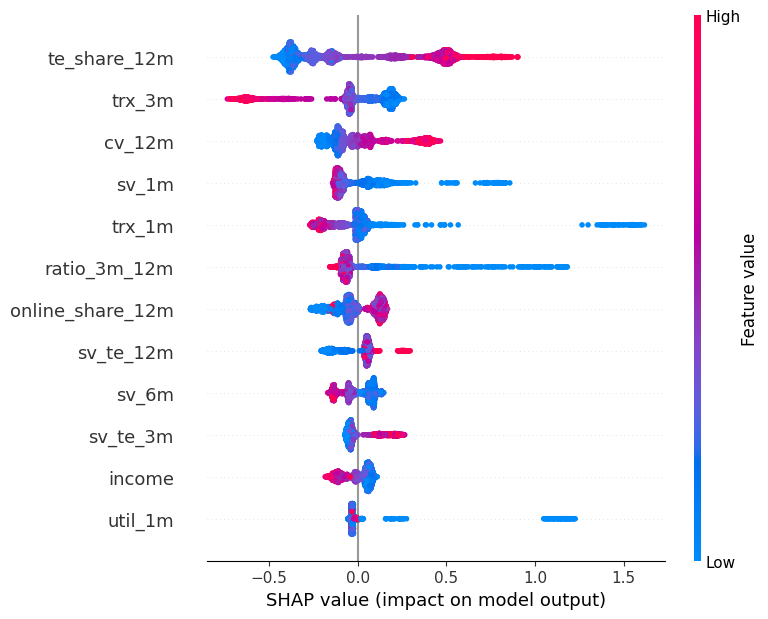

In [63]:
import shap, matplotlib.pyplot as plt
Xte = te[FEATS]
if best == 'LightGBM':
    sv = shap.TreeExplainer(final).shap_values(Xte)
    sv = sv[1] if isinstance(sv, list) else sv
    Xshow = Xte
else:
    prep = final[:-1]
    Xs = pd.DataFrame(prep.transform(Xte), columns=FEATS, index=Xte.index)
    sv = shap.LinearExplainer(final[-1], pd.DataFrame(prep.transform(trva[FEATS]), columns=FEATS)).shap_values(Xs)
    Xshow = Xs
imp = pd.Series(np.abs(sv).mean(0), index=FEATS).sort_values(ascending=False)
print('=== Top 12 driver (mean |SHAP|) ===')
print(imp.head(12))
shap.summary_plot(sv, Xshow, max_display=12, show=False)
plt.tight_layout(); plt.savefig(OUT + 's6_shap_summary.png', dpi=150); plt.show()

te[['user', 'ym', 'score', 'decile', 'target', 'sv_3m', 'run_rate_q', 'sv_next3m', 'te_share_12m']].to_csv(
    OUT + 's6_risk_scores.csv', index=False)

#Report

In [64]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
OUT = '/content/drive/MyDrive/sv_project/'
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
RED, GREEN, GREY, BLUE, ORANGE = '#C0392B', '#2E8B57', '#9E9E9E', '#2F5D8A', '#E08E2B'

tot = pd.read_csv(OUT + 's3_total.csv', index_col=0)
grp = pd.read_csv(OUT + 's3_group.csv', index_col=0)
mcc = pd.read_csv(OUT + 's3_mcc.csv', index_col=[0, 1, 2])
bs  = pd.read_csv(OUT + 's5_bootstrap_group.csv', index_col=0)
rs  = pd.read_csv(OUT + 's6_risk_scores.csv')

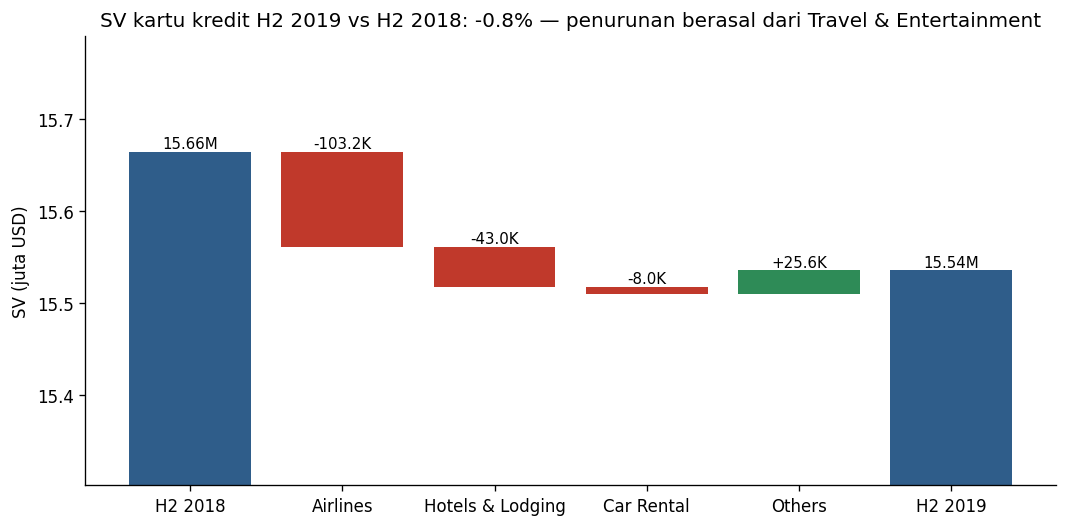

In [65]:
# Chart 1: Waterfall SV H2 2018 -> H2 2019 per kelompok MCC
order = ['Airlines', 'Hotels & Lodging', 'Car Rental', 'Others']
start, end = tot['sv_2018'].iloc[0], tot['sv_2019'].iloc[0]
deltas = grp.loc[order, 'delta']
labels = ['H2 2018'] + order + ['H2 2019']
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(0, start / 1e6, color=BLUE)
run = start
for i, d in enumerate(deltas, start=1):
    ax.bar(i, d / 1e6, bottom=run / 1e6, color=RED if d < 0 else GREEN)
    ax.text(i, (run + max(d, 0)) / 1e6 + 0.004, f'{d/1e3:+,.1f}K', ha='center', fontsize=9)
    run += d
ax.bar(len(labels) - 1, end / 1e6, color=BLUE)
for i, v in [(0, start), (len(labels) - 1, end)]:
    ax.text(i, v / 1e6 + 0.004, f'{v/1e6:,.2f}M', ha='center', fontsize=9)
ax.set_xticks(range(len(labels)), labels)
ax.set_ylim(min(start, end) / 1e6 * 0.985, max(start, end) / 1e6 * 1.008)
ax.set_ylabel('SV (juta USD)')
ax.set_title(f'SV kartu kredit H2 2019 vs H2 2018: {end/start-1:+.1%} — penurunan berasal dari Travel & Entertainment')
plt.tight_layout(); plt.savefig(OUT + 'fig1_waterfall.png', dpi=150); plt.show()

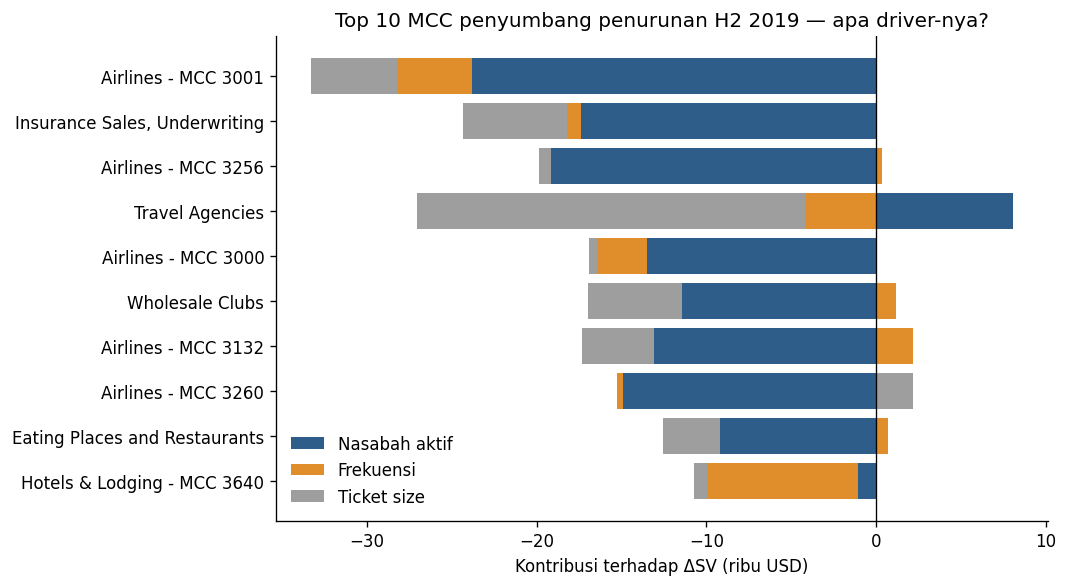

In [66]:
# Chart 2: Driver (nasabah / frekuensi / ticket) untuk top 10 MCC penyumbang penurunan
top = mcc.sort_values('delta').head(10)
top = top.set_index(top.index.get_level_values(2))[['c_users', 'c_freq', 'c_ticket']][::-1] / 1e3
fig, ax = plt.subplots(figsize=(9, 5))
left_neg = np.zeros(len(top)); left_pos = np.zeros(len(top))
for col, color, name in [('c_users', BLUE, 'Nasabah aktif'), ('c_freq', ORANGE, 'Frekuensi'), ('c_ticket', GREY, 'Ticket size')]:
    v = top[col].values
    left = np.where(v < 0, left_neg, left_pos)
    ax.barh(top.index, v, left=left, color=color, label=name)
    left_neg += np.where(v < 0, v, 0); left_pos += np.where(v >= 0, v, 0)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Kontribusi terhadap ΔSV (ribu USD)')
ax.set_title('Top 10 MCC penyumbang penurunan H2 2019 — apa driver-nya?')
ax.legend(loc='lower left', frameon=False)
plt.tight_layout(); plt.savefig(OUT + 'fig2_driver_mcc.png', dpi=150); plt.show()

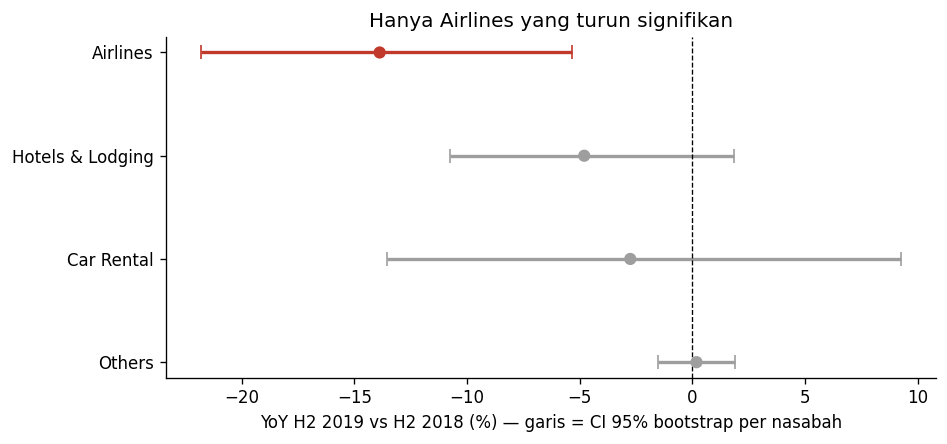

In [67]:
# Chart 3: YoY per kelompok + CI 95% bootstrap
b = bs.loc[order]
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [RED if s == 'TURUN' else GREY for s in b['signifikan']]
for i, (_, r) in enumerate(b.iterrows()):
    ax.errorbar(r['yoy_%'], i, xerr=[[r['yoy_%'] - r['ci_low']], [r['ci_high'] - r['yoy_%']]],
                fmt='none', ecolor=colors[i], elinewidth=2, capsize=4)
ax.scatter(b['yoy_%'], range(len(b)), color=colors, zorder=3, s=40)
ax.axvline(0, color='black', lw=0.8, ls='--')
ax.set_yticks(range(len(b)), b.index); ax.invert_yaxis()
ax.set_xlabel('YoY H2 2019 vs H2 2018 (%) — garis = CI 95% bootstrap per nasabah')
ax.set_title('Hanya Airlines yang turun signifikan')
plt.tight_layout(); plt.savefig(OUT + 'fig3_bootstrap_ci.png', dpi=150); plt.show()

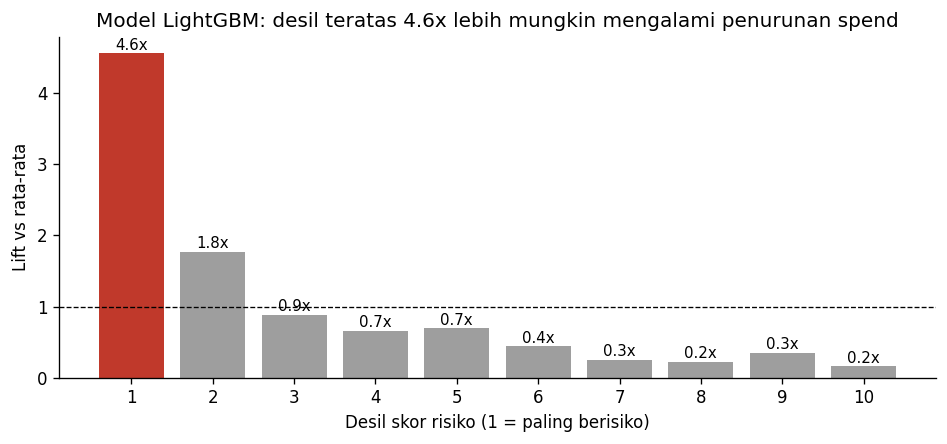

In [68]:
# Chart 4: Lift per desil model
lift = rs.groupby('decile')['target'].mean() / rs['target'].mean()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(lift.index.astype(str), lift.values, color=[RED] + [GREY] * (len(lift) - 1))
ax.axhline(1, color='black', lw=0.8, ls='--')
for i, v in enumerate(lift.values):
    ax.text(i, v + 0.05, f'{v:.1f}x', ha='center', fontsize=9)
ax.set_xlabel('Desil skor risiko (1 = paling berisiko)'); ax.set_ylabel('Lift vs rata-rata')
ax.set_title('Model LightGBM: desil teratas 4.6x lebih mungkin mengalami penurunan spend')
plt.tight_layout(); plt.savefig(OUT + 'fig4_lift.png', dpi=150); plt.show()